In [ ]:
import pandas as pd
import numpy as np


In [ ]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,No,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,"29,85","29,85",No
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,"56,95","1.889,50",No
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,"53,85","108,15",Yes
3,7795-CFOCW,Male,No,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),"42,30","1.840,75",No
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,"70,70","151,65",Yes


In [ ]:
df = df.drop(columns=('customerID'))

In [ ]:
df.isnull().sum()

,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


In [ ]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,"29,85","29,85",No
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,"56,95","1.889,50",No
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,"53,85","108,15",Yes
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),"42,30","1.840,75",No
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,"70,70","151,65",Yes


In [ ]:
df['TotalCharges'] = (
    df['TotalCharges']
    .astype(str)
    .str.replace('.', '', regex=False)
    .str.replace(',', '.', regex=False)
)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)

df['MonthlyCharges'] = (
    df['MonthlyCharges']
    .astype(str)
    .str.replace('.', '', regex=False)
    .str.replace(',', '.', regex=False)
)
df['MonthlyCharges'] = pd.to_numeric(df['MonthlyCharges'], errors='coerce')

df[['tenure', 'MonthlyCharges', 'TotalCharges']].head()

,tenure,MonthlyCharges,TotalCharges
0,1,29.85,29.85
1,34,56.95,1889.50
2,2,53.85,108.15
3,45,42.30,1840.75
4,2,70.70,151.65


In [ ]:
df.isnull().sum()

,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


In [ ]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

binary_cols = ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']
for col in binary_cols:
    df[col] = df[col].map({'Yes': 1, 'No': 0})

In [ ]:
df[['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn']].head()

,Partner,Dependents,PhoneService,PaperlessBilling,Churn
0,1,0,0,1,0
1,0,0,1,0,0
2,0,0,1,1,1
3,0,0,0,0,0
4,0,0,1,1,1


In [ ]:
# Daftar kolom layanan tambahan
service_cols = [
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies'
]

# Hitung jumlah layanan aktif yang digunakan tiap pelanggan
df['Total_Services_Used'] = (df[service_cols] == 'Yes').sum(axis=1)

df[['Total_Services_Used'] + service_cols].head()

,Total_Services_Used,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,1,No,Yes,No,No,No,No
1,2,Yes,No,Yes,No,No,No
2,2,Yes,Yes,No,No,No,No
3,3,Yes,No,Yes,Yes,No,No
4,0,No,No,No,No,No,No


In [ ]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Total_Services_Used
0,Female,No,1,0,1,0,No phone service,DSL,No,Yes,...,No,No,No,Month-to-month,1,Electronic check,29.85,29.85,0,1
1,Male,No,0,0,34,1,No,DSL,Yes,No,...,No,No,No,One year,0,Mailed check,56.95,1889.50,0,2
2,Male,No,0,0,2,1,No,DSL,Yes,Yes,...,No,No,No,Month-to-month,1,Mailed check,53.85,108.15,1,2
3,Male,No,0,0,45,0,No phone service,DSL,Yes,No,...,Yes,No,No,One year,0,Bank transfer (automatic),42.30,1840.75,0,3
4,Female,No,0,0,2,1,No,Fiber optic,No,No,...,No,No,No,Month-to-month,1,Electronic check,70.70,151.65,1,0


In [ ]:
df.to_csv('Telco_Customer_Churn_Cleaned.csv', index=False)

print("File 'Telco_Customer_Churn_Cleaned.csv' berhasil disimpan!")

File 'Telco_Customer_Churn_Cleaned.csv' berhasil disimpan!


/tmp/ipykernel_577/857975977.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(data=df, x='Contract', y='Churn', errorbar=None, palette='Reds_d')


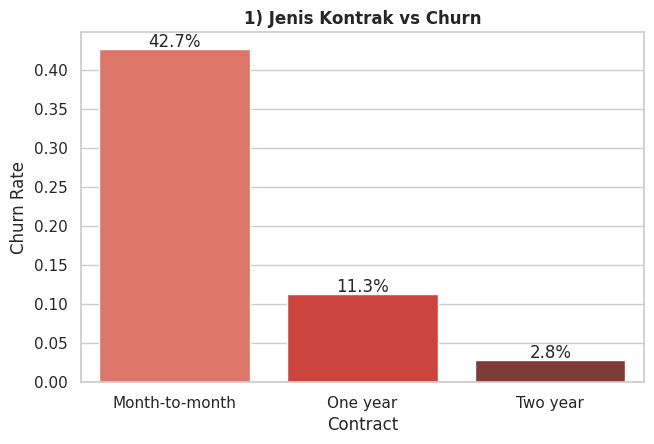

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 10))

#Contract -> churn
plt.subplot(2, 2, 1)
ax1 = sns.barplot(data=df, x='Contract', y='Churn', errorbar=None, palette='Reds_d')
plt.title('1) Jenis Kontrak vs Churn', fontsize=12, fontweight='bold')
plt.xlabel('Contract')
plt.ylabel('Churn Rate')
for p in ax1.patches:
    ax1.annotate(f'{p.get_height()*100:.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='center', xytext=(0, 5), textcoords='offset points')



Text(0, 0.5, 'Densitas')

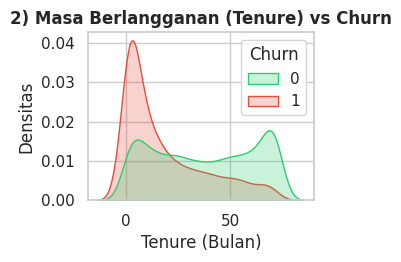

In [ ]:
# tenure -> churn
plt.subplot(2, 2, 2)
sns.kdeplot(data=df, x='tenure', hue='Churn', common_norm=False, palette=['#2ecc71', '#e74c3c'], fill=True)
plt.title('2) Masa Berlangganan (Tenure) vs Churn', fontsize=12, fontweight='bold')
plt.xlabel('Tenure (Bulan)')
plt.ylabel('Densitas')


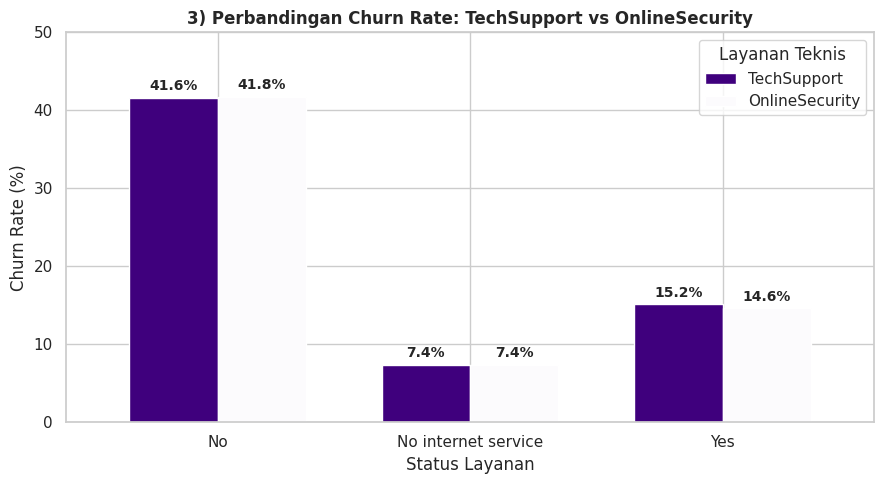

In [ ]:
# Churn Rate (%) untuk TechSupport & OnlineSecurity
data_p3 = {
    'TechSupport': df.groupby('TechSupport')['Churn'].mean() * 100,
    'OnlineSecurity': df.groupby('OnlineSecurity')['Churn'].mean() * 100
}
df_p3 = pd.DataFrame(data_p3)

#Grouped Bar Chart
ax = df_p3.plot(kind='bar', stacked=False, figsize=(9, 5), colormap='Purples_r', width=0.7)

plt.title('3) Perbandingan Churn Rate: TechSupport vs OnlineSecurity', fontsize=12, fontweight='bold')
plt.xlabel('Status Layanan')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.legend(title='Layanan Teknis')
plt.ylim(0, 50)

#label persentase di atas masing-masing bar
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height:.1f}%',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', xytext=(0, 3), textcoords='offset points',
                    fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

/tmp/ipykernel_577/32169743.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax4 = sns.barplot(data=df, x='Total_Services_Used', y='Churn', errorbar=None, palette='Blues_d')


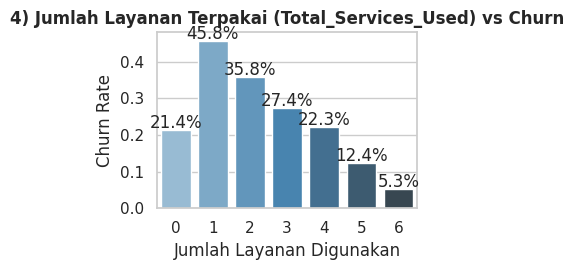

In [ ]:
# Total_Services_Used -> churn
plt.subplot(2, 2, 4)
ax4 = sns.barplot(data=df, x='Total_Services_Used', y='Churn', errorbar=None, palette='Blues_d')
plt.title('4) Jumlah Layanan Terpakai (Total_Services_Used) vs Churn', fontsize=12, fontweight='bold')
plt.xlabel('Jumlah Layanan Digunakan')
plt.ylabel('Churn Rate')
for p in ax4.patches:
    ax4.annotate(f'{p.get_height()*100:.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

Text(0, 0.5, 'Densitas')

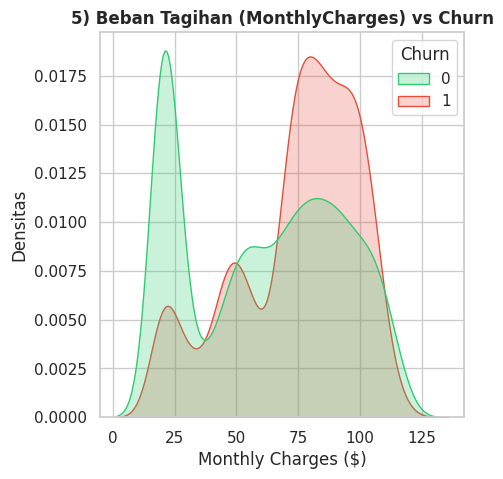

In [ ]:
plt.figure(figsize=(16, 5))

# MonthlyCharges -> churn
plt.subplot(1, 3, 1)
sns.kdeplot(data=df, x='MonthlyCharges', hue='Churn', common_norm=False, palette=['#2ecc71', '#e74c3c'], fill=True)
plt.title('5) Beban Tagihan (MonthlyCharges) vs Churn', fontsize=12, fontweight='bold')
plt.xlabel('Monthly Charges ($)')
plt.ylabel('Densitas')

/tmp/ipykernel_577/3621756654.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax6 = sns.barplot(data=df, x='Churn', y='PaymentMethod', errorbar=None, palette='Oranges_d')


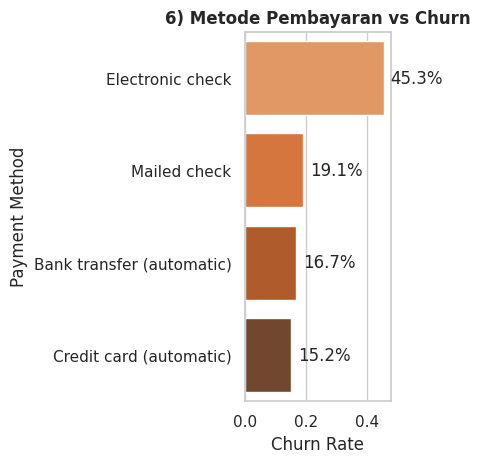

In [ ]:
#PaymentMethod -> churn
plt.subplot(1, 3, 2)
ax6 = sns.barplot(data=df, x='Churn', y='PaymentMethod', errorbar=None, palette='Oranges_d')
plt.title('6) Metode Pembayaran vs Churn', fontsize=12, fontweight='bold')
plt.xlabel('Churn Rate')
plt.ylabel('Payment Method')
for p in ax6.patches:
    ax6.annotate(f'{p.get_width()*100:.1f}%', (p.get_width(), p.get_y() + p.get_height() / 2.),
                 ha='left', va='center', xytext=(5, 0), textcoords='offset points')

/tmp/ipykernel_577/2587337637.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax7 = sns.barplot(data=df, x='Dependents', y='Churn', errorbar=None, palette='Greens_d')


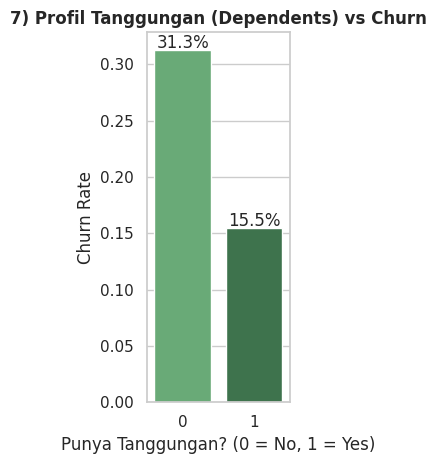

In [ ]:
#Dependents -> churn
plt.subplot(1, 3, 3)
ax7 = sns.barplot(data=df, x='Dependents', y='Churn', errorbar=None, palette='Greens_d')
plt.title('7) Profil Tanggungan (Dependents) vs Churn', fontsize=12, fontweight='bold')
plt.xlabel('Punya Tanggungan? (0 = No, 1 = Yes)')
plt.ylabel('Churn Rate')
for p in ax7.patches:
    ax7.annotate(f'{p.get_height()*100:.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

In [ ]:
# persentase total churn pelanggan
churn_counts = df['Churn'].value_counts(normalize=True) * 100

print("--- Persentase Total Churn Pelanggan ---")
print(f"Active (No): {churn_counts.get(0, 0):.2f}%")
print(f"Churn (Yes): {churn_counts.get(1, 0):.2f}%")

--- Persentase Total Churn Pelanggan ---
Active (No): 73.46%
Churn (Yes): 26.54%
